# Maroc Telecom — analyse financière 2023–2025
États sociaux IAM SA, ratios, comptes du Groupe et scénarios 2026–2030.

**Lecture immédiate :** les résultats, tableaux et graphiques sont déjà enregistrés dans ce notebook.
La version `financial_analysis.html`, placée à côté, s’ouvre dans un navigateur sans Jupyter.

**Pour recalculer :** décompresser le ZIP complet, ouvrir ce notebook dans Jupyter, choisir le noyau
Python de l’environnement du projet, puis **Kernel → Restart Kernel and Run All Cells**.
Installer au préalable `requirements-notebook.txt`. Le lancement Windows est expliqué dans `COMMENT_OUVRIR_LES_FICHIERS.md`.

Les chiffres publiés, les calculs et les hypothèses sont distingués. Les comptes sociaux IAM SA (CGNC)
ne sont jamais additionnés aux comptes consolidés du Groupe (IFRS/KPI).

In [1]:
from pathlib import Path
import sys, os, csv, html
from IPython.display import display, HTML, SVG, Markdown

# Laisser None si Jupyter est lancé dans le dossier du projet ou dans notebooks/.
PROJECT_DIR = None
search = [Path(PROJECT_DIR).expanduser()] if PROJECT_DIR else [Path.cwd(), *Path.cwd().parents]
ROOT = next((p.resolve() for p in search if (p / "src/model.py").is_file()
             and (p / "data/raw/social_statements.csv").is_file()), None)
if ROOT is None:
    raise RuntimeError("Dossier du projet introuvable. Décompressez le ZIP complet, lancez Jupyter "
                       "depuis ce dossier, ou renseignez PROJECT_DIR dans cette cellule.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.pipeline import main
from src.model import read, history, forecasts, dcf
main()
print("Projet trouvé. Les sorties ont été recalculées avec succès.")

États sociaux : 492 observations, 45 contrôles, 0 écarts hors tolérance.
Pipeline OK : CSV, SQLite, graphiques SVG, états sociaux et dashboard générés.
Projet trouvé. Les sorties ont été recalculées avec succès.


In [2]:
# Affichage de tableaux en français : aucune bibliothèque de calcul externe nécessaire.
def nombre(v, percent=False):
    if v is None or v == "":
        return "n.d."
    value = float(v) * (100 if percent else 1)
    return f"{value:,.2f}".replace(",", " ").replace(".", ",") + (" %" if percent else "")

def tableau(rows, columns, title=""):
    # columns : (clé, libellé, format), où format vaut texte, nombre, pourcentage ou ratio.
    out = '<div style="font-family:Arial;color:#222;overflow:auto">'
    if title:
        out += '<h3>' + html.escape(title) + '</h3>'
    out += '<table style="border-collapse:collapse;font-size:13px"><thead><tr>'
    out += ''.join('<th style="padding:9px;background:#eee;text-align:left;border-bottom:1px solid #888">'
                   + html.escape(label) + '</th>' for key,label,kind in columns)
    out += '</tr></thead><tbody>'
    for row in rows:
        out += '<tr>'
        for key,label,kind in columns:
            value = row.get(key, '')
            text = str(value) if kind == 'texte' else nombre(value, kind == 'pourcentage')
            if kind == 'ratio' and value != '':
                text += ' x'
            align = 'left' if kind == 'texte' else 'right'
            out += f'<td style="padding:8px;border-bottom:1px solid #ddd;text-align:{align}">{html.escape(text)}</td>'
        out += '</tr>'
    display(HTML(out + '</tbody></table></div>'))

colonnes_etats = [('libelle','Poste','texte'),('2023','2023','nombre'),
                 ('2024','2024','nombre'),('2025','2025','nombre'),
                 ('variation_25_24','Variation 2025/2024','nombre')]

## 1. États sociaux publiés — IAM SA seule
Source : DEU 2025, pages 233–238. Valeurs nettes pour l’actif; montants en millions MAD.
Les sous-totaux publiés sont conservés. Ils ne doivent pas être additionnés aux lignes de détail.

In [3]:
tableau(read("data/tables/bilan_actif.csv"), colonnes_etats, "Bilan actif net — MDH")

Poste,2023,2024,2025,Variation 2025/2024
Immobilisations en non-valeurs,"860,00","420,00","280,00","-140,00"
Frais préliminaires,"0,00","0,00","0,00","0,00"
Charges à répartir sur plusieurs exercices,"860,00","420,00","280,00","-140,00"
Primes de remboursement des obligations,"0,00","0,00","0,00","0,00"
Immobilisations incorporelles,"1 873,67","2 020,09","2 994,43","974,34"
Immobilisations en recherche et développement,"0,00","0,00","0,00","0,00"
"Brevets, marques, droits et valeurs similaires","1 611,16","1 619,63","2 427,99","808,35"
Fonds commercial,"0,00","0,74","0,56","-0,18"
Autres immobilisations incorporelles,"262,51","399,72","565,88","166,17"
Immobilisations corporelles,"15 031,89","15 081,07","16 479,91","1 398,84"


In [4]:
tableau(read("data/tables/bilan_passif.csv"), colonnes_etats, "Bilan passif — MDH")

Poste,2023,2024,2025,Variation 2025/2024
Capitaux propres,"18 797,72","16 699,29","21 247,67","4 548,38"
Capital social,"5 274,57","5 274,57","5 274,57","0,00"
Réserve légale,"527,46","527,46","527,46","0,00"
Autres réserves,"7 571,94","9 304,56","9 640,27","335,71"
Report à nouveau,"0,00","0,00","0,00","0,00"
Résultat net en instance d'affectation,"0,00","0,00","0,00","0,00"
Résultat net de l'exercice,"5 423,76","1 592,70","5 805,38","4 212,67"
Capitaux propres assimilés,"0,00","0,00","0,00","0,00"
Dettes de financement,"15,19","1,49","3 001,49","3 000,00"
Emprunts obligataires,"0,00","0,00","3 000,00","3 000,00"


In [5]:
tableau(read("data/tables/cpc.csv"), colonnes_etats, "Compte de produits et charges — MDH")

Poste,2023,2024,2025,Variation 2025/2024
Produits d'exploitation,"19 143,77","18 762,24","18 322,24","-440,00"
Ventes de marchandises,"379,58","294,57","260,59","-33,98"
Ventes de biens et services produits,"18 169,58","18 096,03","17 870,93","-225,10"
Chiffre d'affaires,"18 549,16","18 390,61","18 131,52","-259,08"
Variation des stocks de produits,"0,00","0,00","0,00","0,00"
Immobilisations produites pour l'entreprise,"0,00","0,00","0,00","0,00"
Subventions d'exploitation,"0,00","0,00","0,00","0,00"
Autres produits d'exploitation,"22,91","38,86","30,68","-8,19"
Reprises d'exploitation et transferts de charges,"571,70","332,77","160,04","-172,73"
Charges d'exploitation,"11 812,21","11 493,97","11 783,00","289,03"


In [6]:
tableau(read("data/tables/esg.csv"), colonnes_etats, "État des soldes de gestion — MDH")

Poste,2023,2024,2025,Variation 2025/2024
Ventes de marchandises,"379,58","294,57","260,59","-33,98"
Achats revendus de marchandises,"392,22","415,78","288,86","-126,92"
Marge brute sur ventes en l'état,"-12,63","-121,20","-28,26","92,94"
Production de l'exercice,"18 169,58","18 096,03","17 870,93","-225,10"
Ventes de biens et services produits,"18 169,58","18 096,03","17 870,93","-225,10"
Variation des stocks de produits,"0,00","0,00","0,00","0,00"
Immobilisations produites pour l'entreprise,"0,00","0,00","0,00","0,00"
Consommation de l'exercice,"5 569,03","5 569,49","5 664,73","95,24"
Achats consommés de matières et fournitures,"3 049,65","2 877,08","2 798,41","-78,67"
Autres charges externes,"2 519,38","2 692,41","2 866,32","173,91"


In [7]:
tableau(read("data/tables/caf.csv"), colonnes_etats, "CAF et autofinancement — MDH")

Poste,2023,2024,2025,Variation 2025/2024
Résultat net de l'exercice,"5 423,76","1 592,70","5 805,38","4 212,67"
Dotations d'exploitation éligibles CAF,"3 074,74","2 918,94","2 891,88","-27,06"
Dotations financières éligibles CAF,"2,14","33,44","1 153,58","1 120,14"
Dotations non courantes éligibles CAF,"626,70","621,13","318,98","-302,14"
Reprises d'exploitation éligibles CAF,"0,78","0,73","0,74","0,01"
Reprises financières éligibles CAF,"1,46","2,14","33,44","31,30"
Reprises non courantes éligibles CAF,"168,26","165,82","150,41","-15,41"
Produits de cessions d'immobilisations,"2,77","4,20","18,71","14,51"
VNA des immobilisations cédées,"0,27","0,11","444,75","444,64"
Capacité d'autofinancement (CAF),"8 954,34","4 993,44","10 411,27","5 417,84"


In [8]:
tableau(read("data/tables/tableau_financement.csv"),
        [('libelle','Poste','texte')] +
        [(f'{side}_{year}',f'{year} {label}','nombre')
         for year in (2023,2024,2025)
         for side,label in [('emplois','Emplois'),('ressources','Ressources')]],
        "Tableau de financement — MDH")

Poste,2023 Emplois,2023 Ressources,2024 Emplois,2024 Ressources,2025 Emplois,2025 Ressources
Autofinancement,n.d.,"7 029,40",n.d.,"1 302,30",n.d.,"9 154,28"
Capacité d'autofinancement,n.d.,"8 954,34",n.d.,"4 993,44",n.d.,"10 411,27"
Distributions de bénéfices,n.d.,"1 924,93",n.d.,"3 691,14",n.d.,"1 256,99"
Cessions et réductions d'immobilisations,n.d.,"78,43",n.d.,"4,35",n.d.,"1 328,85"
Augmentation des dettes de financement,n.d.,"13,69",n.d.,"-13,69",n.d.,"3 000,00"
TOTAL RESSOURCES STABLES,n.d.,"7 121,53",n.d.,"1 292,96",n.d.,"13 483,13"
Acquisitions et augmentations d'immobilisations,"3 552,55",n.d.,"4 606,01",n.d.,"6 419,47",n.d.
Acquisitions d'immobilisations incorporelles,"292,83",n.d.,"452,39",n.d.,"1 342,65",n.d.
Acquisitions d'immobilisations corporelles,"2 873,53",n.d.,"2 677,57",n.d.,"3 964,21",n.d.
Acquisitions d'immobilisations financières,"386,14",n.d.,"56,89",n.d.,"966,87",n.d.


## 2. Les 19 ratios financiers, avec leur formule
Ratios calculés sur les comptes sociaux IAM SA. Les taux sont affichés en %, les autres rapports en fois.
Le ROE et le ROA utilisent les capitaux propres et l’actif de clôture, non leurs moyennes.

In [9]:
ratios_sociaux = read("data/tables/ratios_financiers.csv")
for unite, titre, format_nombre in [("%","Ratios en pourcentage","pourcentage"),
                                    ("fois","Ratios en fois","ratio")]:
    tableau([r for r in ratios_sociaux if r["unite"] == unite],
            [('ratio','Ratio','texte'),('formule','Formule','texte')] +
            [(str(y),str(y),format_nombre) for y in (2023,2024,2025)] +
            [('interpretation','Explication','texte')],titre)

Ratio,Formule,2023,2024,2025,Explication
Croissance du chiffre d’affaires,CA / CA de l’année précédente − 1,n.d.,"-0,85 %","-1,41 %",Évolution annuelle du CA; 2023 indisponible sans 2022.
Taux de valeur ajoutée,Valeur ajoutée / chiffre d’affaires,"67,86 %","67,45 %","67,16 %",Part du CA correspondant à la valeur ajoutée sociale.
Marge brute d’exploitation,EBE / chiffre d’affaires,"54,52 %","55,05 %","54,40 %",Performance avant dotations et résultat financier.
Marge d’exploitation,Résultat d’exploitation / chiffre d’affaires,"39,52 %","39,52 %","36,07 %",Performance après dotations d’exploitation.
Marge nette,Résultat net / chiffre d’affaires,"29,24 %","8,66 %","32,02 %",Inclut résultats financier et non courant; pas une marge récurrente.
Rentabilité des capitaux propres — ROE,Résultat net / capitaux propres de clôture,"28,85 %","9,54 %","27,32 %","Rentabilité comptable sur capitaux propres de clôture, non moyens."
Rentabilité de l’actif — ROA,Résultat net / actif total de clôture,"14,10 %","3,99 %","14,33 %","Rentabilité comptable de l’actif, affectée par les éléments non récurrents."
Autonomie financière,Capitaux propres / actif total,"48,85 %","41,85 %","52,46 %",Part du bilan financée par les capitaux propres.
Poids des passifs hors capitaux propres,(Total passif − capitaux propres) / total passif,"51,15 %","58,15 %","47,54 %",Inclut dettes d’exploitation et provisions; distinct de la seule dette financière.
Liquidité immédiate,Trésorerie actif / (passif circulant + trésorerie passif),"0,45 %","1,17 %","2,10 %",Trésorerie disponible au bilan rapportée aux passifs à court terme.


Ratio,Formule,2023,2024,2025,Explication
Rotation de l’actif,Chiffre d’affaires / actif total de clôture,"0,48 x","0,46 x","0,45 x",CA produit pour un dirham d’actif de clôture.
Liquidité générale,(Actif circulant + trésorerie actif) / (passif circulant + trésorerie passif),"0,41 x","0,36 x","0,52 x",Inférieure à 1 sur les trois années : examiner les échéances; ce seul ratio ne prouve pas une insolvabilité.
Liquidité réduite,(Actif circulant − stocks + trésorerie actif) / passifs à court terme,"0,40 x","0,35 x","0,50 x","Même périmètre que la liquidité générale, hors stocks."
Couverture des immobilisations,Financement permanent / actif immobilisé net,"0,62 x","0,53 x","0,76 x",Inférieure à 1 : fonds de roulement fonctionnel négatif sur bilan net.
Dette financière brute / capitaux propres,(Dettes de financement + trésorerie passif) / capitaux propres,"0,38 x","0,73 x","0,22 x",Définition sociale simplifiée; ne pas confondre avec la dette nette du Groupe.
Dette financière nette / EBE,(Dettes de financement + trésorerie passif − trésorerie actif) / EBE,"0,69 x","1,17 x","0,44 x","Dette nette simplifiée hors placements, divisée par l’EBE social."
Couverture des charges d’intérêts,EBE / charges d’intérêts,"34,40 x","25,94 x","31,96 x","Couverture comptable des intérêts par l’EBE, pas un covenant bancaire."


In [10]:
tableau(read("data/tables/equilibre_financier.csv"),
        [('indicateur','Indicateur','texte')] + [(str(y),str(y),'nombre') for y in (2023,2024,2025)],
        "Fonds de roulement, besoin de financement global et trésorerie — MDH")

Indicateur,2023,2024,2025
Financement permanent,"18 824,96","16 743,41","24 265,62"
Actif immobilisé net,"30 355,15","31 586,65","32 045,21"
Fonds de roulement fonctionnel,"-11 530,19","-14 843,24","-7 779,59"
Actif circulant hors trésorerie,"8 033,01","8 047,98","8 113,50"
Passif circulant hors trésorerie,"12 614,11","11 006,19","14 509,35"
Besoin de financement global,"-4 581,10","-2 958,21","-6 395,85"
Trésorerie nette,"-6 949,09","-11 885,04","-1 383,74"


**Lecture :** l’EBE social baisse en 2025, tandis que le résultat net augmente avec le redressement
du résultat non courant. La rentabilité nette ne mesure donc pas uniquement l’activité récurrente.
La liquidité générale reste inférieure à 1; les échéances et le cycle d’exploitation doivent être examinés.
Ces observations ne constituent pas un avis d’audit.

## 3. Groupe consolidé — périmètre distinct des comptes sociaux
Les séries IFRS et KPI ajustés ne sont pas confondues : en 2024, le CA IFRS S2 est de 36 699 MDH,
contre 36 704 MDH dans la série KPI S1. Le dictionnaire documente les écarts entre publications.

Année,CA IFRS,CA KPI,EBITDA ajusté,EBITA ajusté,Résultat net part Groupe IFRS
2023,"36 786,00","36 786,00","19 369,00","12 226,00","5 283,00"
2024,"36 699,00","36 704,00","19 188,00","12 092,00","1 801,00"
2025,"36 681,00","36 681,00","18 493,00","11 547,00","6 968,00"


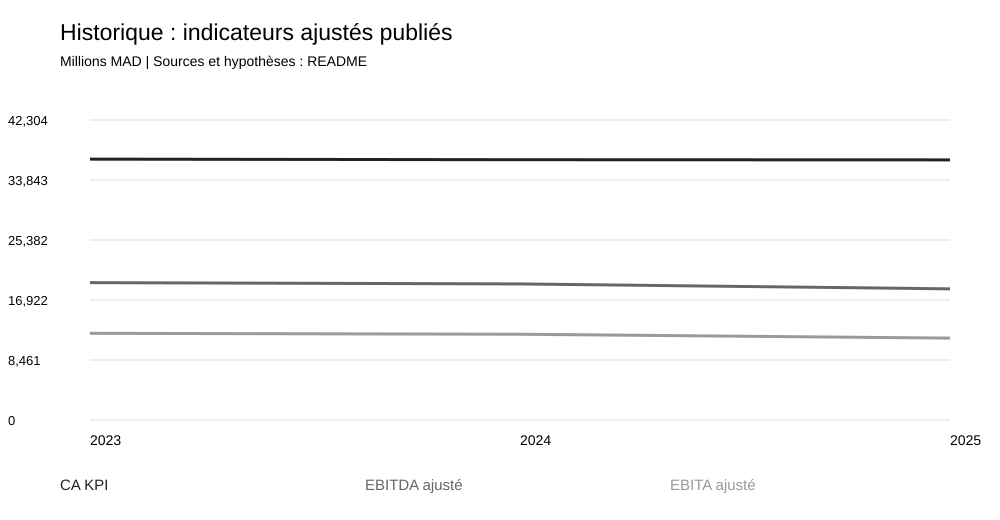

In [11]:
groupe = [dict(annee=y, **v) for y,v in history().items()]
tableau(groupe,[('annee','Année','texte'),('revenue_ifrs','CA IFRS','nombre'),
               ('revenue_kpi','CA KPI','nombre'),('ebitda_adjusted','EBITDA ajusté','nombre'),
               ('ebita_adjusted','EBITA ajusté','nombre'),('net_income_group','Résultat net part Groupe IFRS','nombre')],
        "Indicateurs du Groupe — MDH")
display(SVG(filename=str(ROOT / "charts/historical.svg")))

## 4. Scénarios 2026–2030 et DCF — hypothèses de l’auteur
Prévisions rétrospectives sur base FY2025. Aucune publication 2026 n’est intégrée.
Les hypothèses sont dans `config/scenarios.csv`; elles ne sont pas des engagements de Maroc Telecom.
Les trois scénarios sont calculés séparément, sans mélanger leurs flux.

In [12]:
hypotheses = read("config/scenarios.csv")
tableau([r for r in hypotheses if r['year']=='2026'],
        [('scenario','Scénario','texte'),('revenue_growth','Croissance CA','pourcentage'),
         ('ebitda_margin','Marge EBITDA','pourcentage'),('capex_total_ratio','CAPEX total / CA','pourcentage'),
         ('tax_rate','Impôt normatif','pourcentage'),('wacc','WACC','pourcentage'),
         ('terminal_growth','Croissance perpétuelle','pourcentage')],
        "Hypothèses 2026, constantes jusqu’en 2030 dans le modèle")
projections = forecasts(history(), hypotheses)
for scenario in ['prudent','central','favorable']:
    tableau([r for r in projections if r['scenario']==scenario],
            [('year','Année','texte'),('revenue','CA','nombre'),('ebitda','EBITDA','nombre'),
             ('capex_total','CAPEX total','nombre'),('delta_nwc','Variation BFR','nombre'),('fcff','FCFF','nombre')],
            f"Scénario {scenario} — projections en MDH")

Scénario,Croissance CA,Marge EBITDA,CAPEX total / CA,Impôt normatif,WACC,Croissance perpétuelle
prudent,"0,00 %","48,00 %","28,00 %","35,00 %","11,50 %","1,00 %"
central,"2,50 %","51,00 %","26,00 %","35,00 %","10,00 %","2,00 %"
favorable,"4,50 %","53,00 %","24,00 %","35,00 %","9,00 %","2,50 %"


Année,CA,EBITDA,CAPEX total,Variation BFR,FCFF
2026,"36 681,00","17 606,88","10 270,68","0,00","3 613,08"
2027,"36 681,00","17 606,88","10 270,68","0,00","3 613,08"
2028,"36 681,00","17 606,88","10 270,68","0,00","3 613,08"
2029,"36 681,00","17 606,88","10 270,68","0,00","3 613,08"
2030,"36 681,00","17 606,88","10 270,68","0,00","3 613,08"


Année,CA,EBITDA,CAPEX total,Variation BFR,FCFF
2026,"37 598,02","19 174,99","9 775,49","18,34","5 170,19"
2027,"38 537,98","19 654,37","10 019,87","18,80","5 299,44"
2028,"39 501,43","20 145,73","10 270,37","19,27","5 431,93"
2029,"40 488,96","20 649,37","10 527,13","19,75","5 567,73"
2030,"41 501,18","21 165,60","10 790,31","20,24","5 706,92"


Année,CA,EBITDA,CAPEX total,Variation BFR,FCFF
2026,"38 331,64","20 315,77","9 199,59","33,01","6 521,70"
2027,"40 056,57","21 229,98","9 613,58","34,50","6 815,17"
2028,"41 859,11","22 185,33","10 046,19","36,05","7 121,86"
2029,"43 742,77","23 183,67","10 498,27","37,67","7 442,34"
2030,"45 711,20","24 226,94","10 970,69","39,37","7 777,25"


Scénario,"Valeur d’entreprise, MDH",WACC,Croissance perpétuelle,Part terminale
prudent,"33 354,01","11,50 %","1,00 %","60,46 %"
central,"65 687,57","10,00 %","2,00 %","68,78 %"
favorable,"107 254,17","9,00 %","2,50 %","74,32 %"


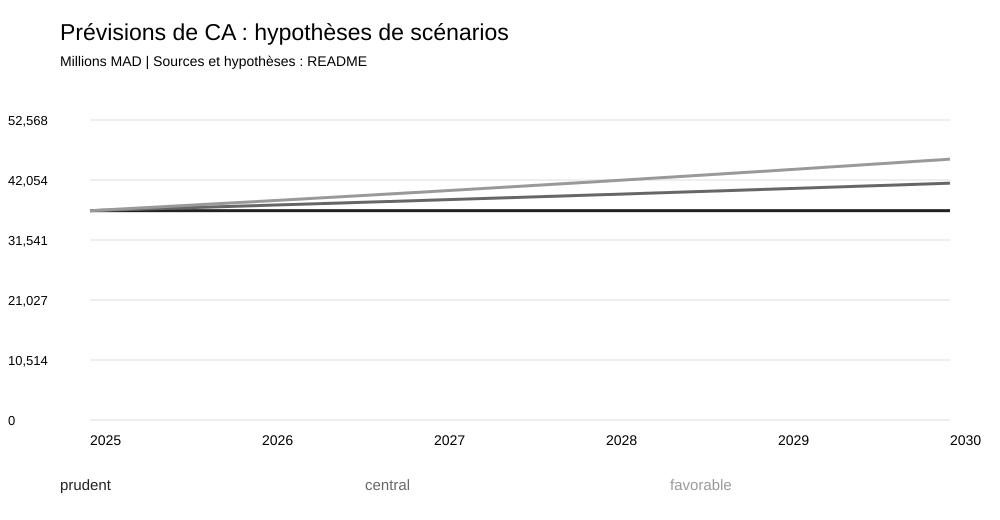

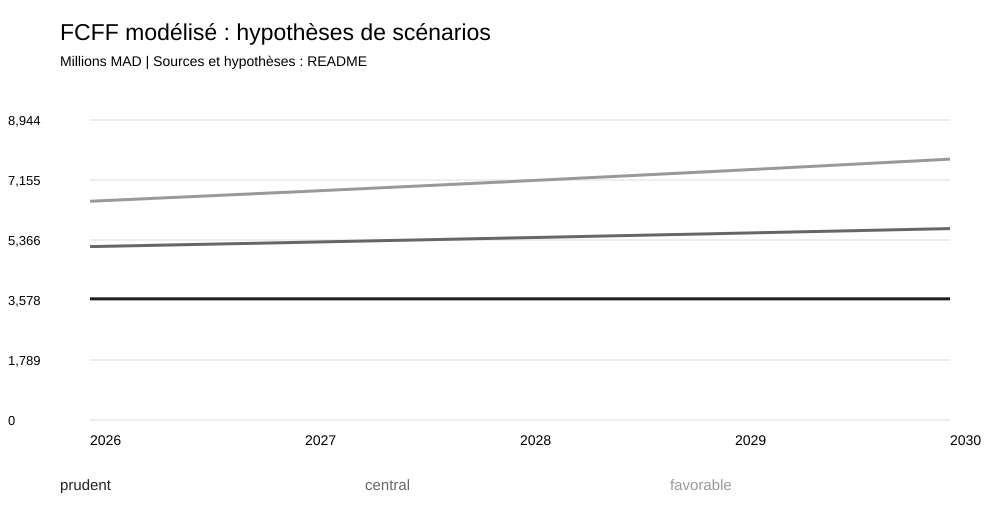

In [13]:
valorisations = [dcf([r for r in projections if r['scenario']==s])
                for s in ['prudent','central','favorable']]
tableau(valorisations,[('scenario','Scénario','texte'),('enterprise_value','Valeur d’entreprise, MDH','nombre'),
                      ('wacc','WACC','pourcentage'),('terminal_growth','Croissance perpétuelle','pourcentage'),
                      ('terminal_share','Part terminale','pourcentage')],
        "DCF pédagogique au 31/12/2025")
display(SVG(filename=str(ROOT / "charts/forecast.svg")))
display(SVG(filename=str(ROOT / "charts/fcff.svg")))

FCFF = EBIT × (1 − impôt normatif) + D&A − CAPEX − variation du BFR.
Le DCF actualise les flux de fin d’année et une valeur terminale de Gordon-Shapiro.
Il s’arrête à la valeur d’entreprise consolidée : aucun cours cible n’est calculé.
Les limites sur les minoritaires et IFRS 16 figurent dans `docs/methodology.md`.

## 5. Requête SQL sur les états sociaux

In [14]:
import sqlite3
with sqlite3.connect(str(ROOT / "data/processed/analysis.sqlite")) as con:
    query = """
    SELECT year AS annee,
      MAX(CASE WHEN statement='CPC' AND code='CA' THEN value END)/1000 AS ca,
      MAX(CASE WHEN statement='ESG TFR' AND code='V' THEN value END)/1000 AS ebe,
      MAX(CASE WHEN statement='CPC' AND code='XIII' THEN value END)/1000 AS resultat_net
    FROM social_reported GROUP BY year ORDER BY year
    """
    cur = con.execute(query)
    sql_rows = [dict(zip([c[0] for c in cur.description], row)) for row in cur.fetchall()]
tableau(sql_rows,[('annee','Année','texte'),('ca','CA social','nombre'),
                  ('ebe','EBE social','nombre'),('resultat_net','Résultat net social','nombre')],
        "Résultats SQL — MDH")

Année,CA social,EBE social,Résultat net social
2023,"18 549,16","10 113,91","5 423,76"
2024,"18 390,61","10 123,21","1 592,70"
2025,"18 131,52","9 863,10","5 805,38"


## 6. Contrôles et sources

In [15]:
checks = read("data/processed/statement_checks.csv")
assert len(checks) == 45
assert all(r['resultat'] == 'OK' for r in checks)
print("45 rapprochements sociaux dans la tolérance de 0,005 MDH.")
import subprocess
result = subprocess.run([sys.executable,"-m","unittest","discover","-s","tests","-v"],
                        cwd=ROOT, capture_output=True, text=True, encoding='utf-8', errors='replace',
                        env={**os.environ, 'PYTHONIOENCODING':'utf-8'})
print(result.stdout + result.stderr)
result.check_returncode()

45 rapprochements sociaux dans la tolérance de 0,005 MDH.


test_balance (test_model.ModelTests.test_balance) ... ok
test_constant_cashflow (test_model.ModelTests.test_constant_cashflow) ... ok
test_forecast_and_dcf (test_model.ModelTests.test_forecast_and_dcf) ... ok
test_outputs (test_model.ModelTests.test_outputs) ... ok
test_reconciliations (test_model.ModelTests.test_reconciliations) ... ok
test_source_integrity (test_model.ModelTests.test_source_integrity) ... ok
test_financing (test_reader_report.ReadableReportTests.test_financing) ... ok
test_ratio_labels_and_values (test_reader_report.ReadableReportTests.test_ratio_labels_and_values) ... ok
test_report_contains_every_statement (test_reader_report.ReadableReportTests.test_report_contains_every_statement) ... ok
test_all_reconciliations (test_statements.StatementTests.test_all_reconciliations) ... ok
test_dashboard_and_powerbi_values (test_statements.StatementTests.test_dashboard_and_powerbi_values) ... ok
test_published_controls (test_statements.StatementTests.test_published_controls) .

In [16]:
tableau(read("data/raw/sources.csv"),
        [('source_id','Source','texte'),('title','Publication','texte'),
         ('locator','Tableau / pages','texte'),('url','Lien','texte')],
        "Sources vérifiées et localisateurs")

Source,Publication,Tableau / pages,Lien
S1,"Chiffres clés officiels, série ajustée affichée en 2025",Tableau 2023-2025,https://www.iam.ma/en/groupe-maroc-telecom/chiffre-cl%C3%A9s
S2,Rapport financier 2025,"Pages imprimées 4, 23-25 (PDF indices 3,22-24)",https://www.iam.ma/documents/66341/0/Maroc%2BTelecom%2B-%2BRapport%2Bfinancier%2B2025%2B%281%29.pdf/0d3b0317-f0fe-8d99-99d3-7ecef52e0bdd?t=1772025169628
S3,Communiqué FY2025,Résultats consolidés ajustés du Groupe,https://www.iam.ma/documents/66341/0/Maroc%2BTelecom%2B-%2BCP%2BR%C3%A9sultats%2BFY2025.pdf/6556f1e8-34dd-a6cc-7568-07cd20411626?t=1770958103350
S4,"Maroc Telecom DEU 2025, comptes sociaux IAM SA",Pages imprimées 233-238,https://www.ammc.ma/sites/default/files/Maroc_Telecom_Document_enregistrement_universel_2025.pdf


## Fichiers pour une lecture sans logiciel de programmation
- `LIRE_LES_TABLEAUX.html` : tous les états et ratios, ouverts dans un navigateur.
- `reports/Rapport_Court_Maroc_Telecom.pdf` : synthèse en cinq pages.
- `workbook/Maroc_Telecom_Etats_Sociaux.xlsx` : dix onglets, formules et graphiques.
- `dashboards/dashboard.html` : dashboard interactif local.

L’ETIC complet reste dans le document officiel. Le projet PBIP est un fichier de développement Power BI;
son affichage dans Desktop n’a pas été validé et aucun PBIX final n’est revendiqué.